<a href="https://colab.research.google.com/github/cduffy57/Github-and-Jupyter-setup/blob/main/EDA_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA Assignment
This assignment asks you to do use exploratory data analysis to answer some questions about various datasets. When you're finished, submit the Notebook file to the assignment section in Canvas.  

Let's start by important some libraries.

In [1]:
# You'll need pandas and matplotlib.pyplot and seaborn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



## PART 1: The Titanic
### Introduction:
We looked at the Titanic dataset earlier in the course, but we didn't do any visualization of the data. Using things you just learned in the EDA Notebook, you'll revisit the dataset and create a few visualizations.


### Step 1. Read the dataset from the variable `titanic_df_URL`. Assign it to a variable named `titanic_df`.

In [2]:
titanic_df_URL = "https://raw.githubusercontent.com/bsmith-classroom/datasets/main/titanic3.csv"

# Do you remember how to read a .csv file into a DataFrame?
titanic_df = pd.read_csv(titanic_df_URL)   # Your code replaces the ""

titanic_df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


### Step 2. Create a bar chart displaying the number of males and females
There are a few ways to make bar charts, but all of them need two things:

1. A list or series of categorical values (e.g., ['female', 'male']).
2. The counts for each value in the list/series (e.g., [843, 466]).

We'll need to compute the counts in most cases. One way to do that: `value_counts()`. Let's use it to get the counts for male and females.



In [3]:
# call value_counts() on the titanic data's sex column below
# and assign it to gender_counts
gender_counts = titanic_df['sex'].value_counts() # YOUR CODE HERE to get values_counts on 'sex'

# what type is gender_counts?
print("The type of gender_counts is:", type(gender_counts))

# doing a type check, don't delete the line below
assert isinstance(gender_counts, pd.Series), "gender_counts should be of type 'pandas.core.series.Series' "

display(gender_counts)

The type of gender_counts is: <class 'pandas.core.series.Series'>


,count
sex,
male,843
female,466


You shouldn't get an error above. And you should see that the gender_counts is a pandas `Series`. `value_counts` returns a Series of counts for each unique value in the column you provided. That's great, but our plot methods often want to work on `DataFrame`s. A simple way to convert the value_counts() Series to a DataFrame is to use `reset_index(). That will create a new column with an index and let us work with the sex and count columns as we've done in other assignments. The conversion is done for you below.

In [4]:
# reset the index and assign it back. It'll now be a DataFrame
gender_counts = gender_counts.reset_index()
display(gender_counts)

# make sure it's a dataframe
print("The type of gender_counts is:", type(gender_counts))


,sex,count
0,male,843
1,female,466


The type of gender_counts is: <class 'pandas.core.frame.DataFrame'>


This looks like a lot of work just ot make a bar plot. But we need to know the counts for each unique value in `sex`. Now that we have them, we can make a plot.  



#### Plotting from a DataFrame
DataFrame's have a method associated with them named `plot()`. `plot` takes a few basic arguments:
- `kind`: This is where you specify the type of plot you want (e.g., 'bar', 'hist', 'box', 'pie', etc.).
- `x`: a column to use on the x-axis
- `y`: a column to use for the y-axis  

The function call would look like this:
```
dataFrame.plot(kind='bar', x='data_to_count_column', y='counts_of_data_column`)
```
We made a DataFrame named `gender_counts` with two columns, `sex` and `count`. Make a bar plot using that DataFrame.

<Axes: xlabel='sex'>

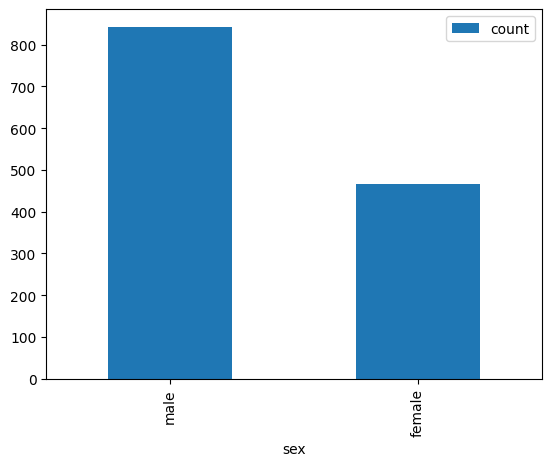

In [5]:
# Write the code to make a bar plot of men and women on the Titanic
gender_counts.plot(kind='bar', x= 'sex', y= 'count')

Hopefully, you see a bar plot with male and female on the x-axis, and the counts on the y-axis.   

#### Using matplotlib's `bar`.

Let's use pyplot's `bar` to make a similar plot. We imported the library as `plt`, and there's a function in it called `bar()`. `bar` takes two basic arguments:
- A list or series of categorical data names for the x-axis
- A list or series of counts for the y-axis

That sounds just like what we did above. The only difference is that we don't call the function on the DataFrame. Here, we have to provide the DataFrame's columns as arguments. Something like this:

```
plt.bar(df['data_to_count_column'], df['counts_of_data_column])
```

Try making a plt.bar plot below using gender_counts.

<BarContainer object of 2 artists>

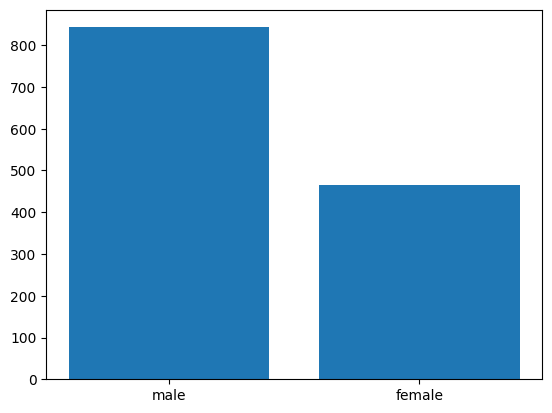

In [6]:
# Use plt.bar to generate a plot of male and female passengers
plt.bar(gender_counts['sex'], gender_counts['count'])

### Step 4. Create a scatterplot showing the fare each person paid against their age

Scatterplots show replationships between variables. In this case, we want to see how fares vary with age. This might show us something like older people tend to buy more expensive seats.  

Like bar charts, there are different ways to make scatterplots. One is to call `plot` on a DataFrame with `kind=scatter`. This will look very similar the bar chart we made above.   Look back at that code if needed, and use it to start making the scatterplot.

<Axes: xlabel='age', ylabel='fare'>

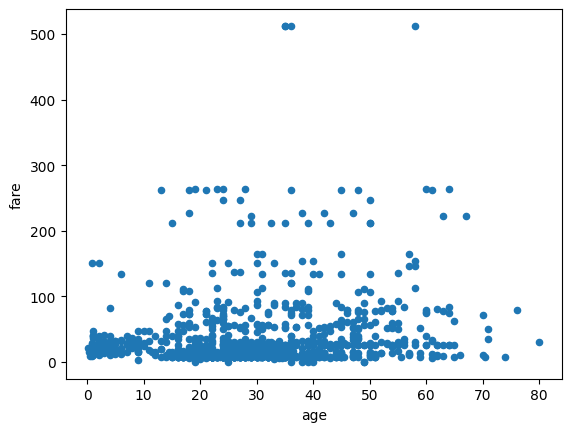

In [7]:
# Your scatterplot code goes below. Put age on the x-axis, fare on the y-axis
titanic_df.plot(kind='scatter', x= 'age', y= 'fare')

What do you see in the plot? One thing seems clear: A lot of people went with the cheaper fares.  

Maybe we'd see a difference by gender? Did more men buy expensive seats? Let's look by creating a plot that splits age and fare by gender. We can do this by plotting two scatterplots, one with values for men, the other with the women's values. We can change the color of the points using the argument `c=`. Try doing this below.

Hint:
1. You'll make two calls to `plt.scatter()`.
2. You need to use some filtering to pull the DateFrame apart into a DataFrame containing only women, the only containing only men.

Text(0, 0.5, 'Fare paid')

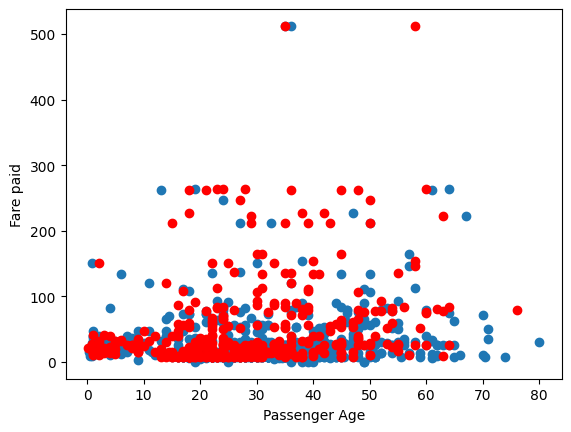

In [8]:
titanic_men = titanic_df[titanic_df['sex'] == 'male']
titanic_women = titanic_df[titanic_df['sex'] == 'female']

# call plt.scatter twice. Once for men, the other for women. And for one of thesem set 'c=red' or
# any other color. You just want to have men look different from women on the plot
plt.scatter(titanic_men['age'], titanic_men['fare'])
plt.scatter(titanic_women['age'], titanic_women['fare'], c = 'red')

plt.xlabel('Passenger Age')
plt.ylabel("Fare paid")

### Step 5. How many people survived?
Why don't we make a bar chart for the survivors.

,count
survived,
0,809
1,500


<Axes: xlabel='survived'>

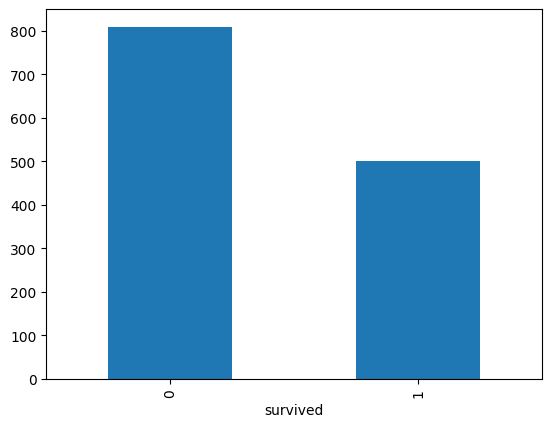

In [9]:
# plot a bar chart of survivors/deceased
titanic_survived = titanic_df['survived'].value_counts().sort_index()

titanic_survived.columns = ['survived', 'count']

display(titanic_survived)

titanic_survived.plot(kind='bar', x= 'survived', y= 'count')

That looks fine, but you might have 0 and 1 as the x-axis labels. Those aren't useful. Change those to more meaningful labels using `plt.xticks()`.

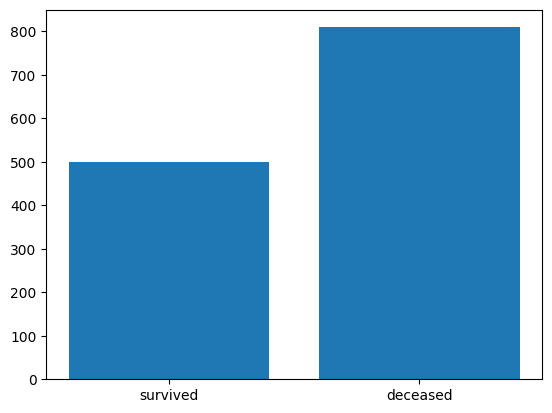

In [10]:
# plot a bar chart of survivors/deceased

# Make a list with two items, a string for non-survivors and a string for survivors.
new_x_ticks = ['survived', 'deceased']

# the command below creates a *range*...basically a list of numbers from
# to some number. Here, some number is the length of the new_x_labels list.
# .x_ticks uses this range to count off where to place the new_x_labels.
new_x_ticks_range = range(0, len(new_x_ticks))

# Use plt.xticks() below with new_x_ticks_range and new_x_ticks
plt.bar(new_x_ticks_range, [titanic_survived[1], titanic_survived[0]])
plt.xticks(new_x_ticks_range, new_x_ticks)
plt.show()

That will give you more meaningful tick names on the x-axis. Now add some additional things to the plot like meaningful text using
- plt.xlabel()
- plt.ylabel()
- plt.title()

And if you want you can rotate the angle of the xticks by adding `rotation=<your angle here>` in the `plt.xticks()`call.

### Step 6. Create a histogram of the paid fares

Text(0.5, 1.0, 'Fare by Age')

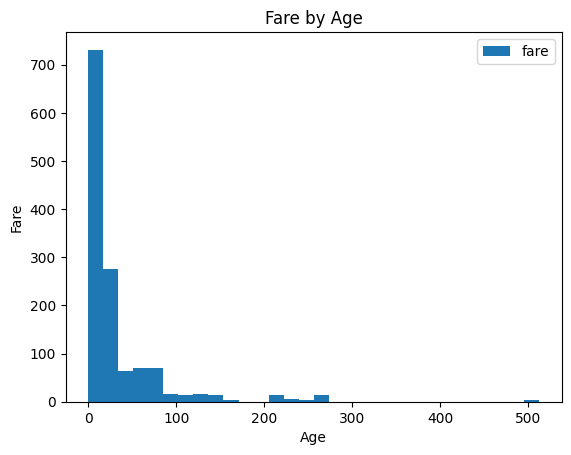

In [16]:
# use plot(kind='hist') to make a histogram. You can use bins= to change the
# bin size...that might make the distribution more (or less) apparent
# also, use plt.xlabel, plt.ylabel, and plt.title to make the plot more readable.

titanic_df.plot(kind = 'hist', x = 'age', y = 'fare', bins = 30)
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Fare by Age')

### BONUS: Create your own question and visualize it.

## Part II: Chipotle
Now we're going to use a dataset of Chipotle items to make a few visualizations. We'll load the data from a github repo (thanks, Kevin Markham!).

### Step 1: Reading the data
One thing you should notice about the URL (see the code below) is that the file is called chipotle.**tsv**. This is a tab-separated file vs. the comma-separated files we've seen so far. Luckily, we can give `read_csv()` an argument called `sep=`. That let's us tell the reader that data are separated by something other than a comma.   

For tabs, set `sep='\t'`.

In [17]:
# we're loading data from Kevin Markham's git repo (thanks!). The URL is below, load it into a pandas dataframe
# called chipotle_df
chipotle_URL = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv"

# Look at the URL...notice this is a .tsv file. It's tab separated vs. comma separated. Luckily,
# the same read_csv() function we've been using takes an additional argument, sep=. Set that to '\t'.
chipotle_df = pd.read_csv(chipotle_URL, sep='\t')    # READ THE TSV FILE


### Step 2: Looking at the first 10 entries
Take a look at the first 10 rows of data.

In [18]:
# display the first 10 rows
chipotle_df.head(10)

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98
5,3,1,Chicken Bowl,"[Fresh Tomato Salsa (Mild), [Rice, Cheese, Sou...",$10.98
6,3,1,Side of Chips,NaN,$1.69
7,4,1,Steak Burrito,"[Tomatillo Red Chili Salsa, [Fajita Vegetables...",$11.75
8,4,1,Steak Soft Tacos,"[Tomatillo Green Chili Salsa, [Pinto Beans, Ch...",$9.25
9,5,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Black Beans, Pinto...",$9.25


### Step 3: Make a bar plot of the **top 5** items bought.
The data columns show that we're looking at customer orders and what was purchased in each. We might want to know what items are being purchased the most. Let's specifically ask for the top five items sold in the dataset.

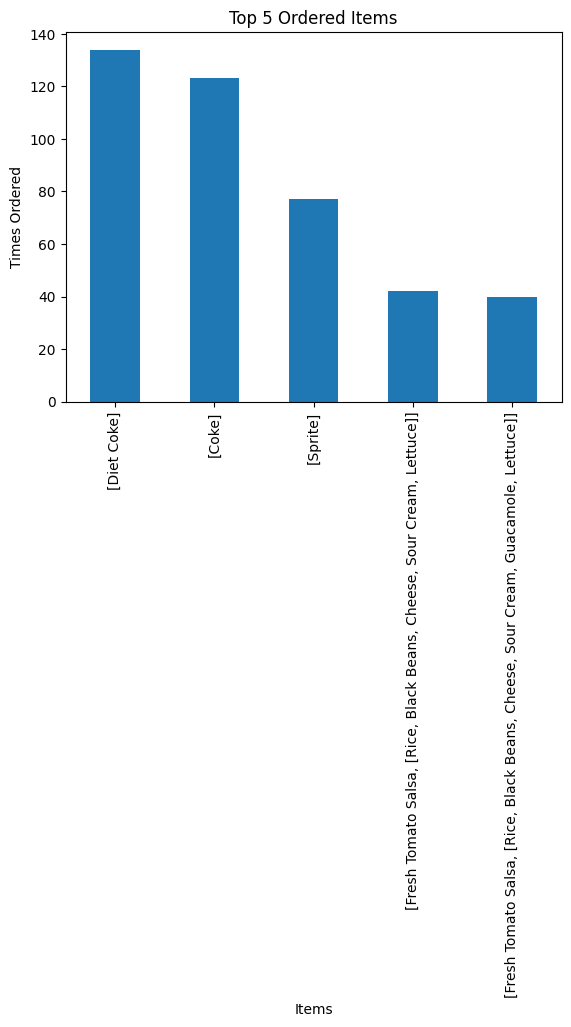

In [26]:
# You're going to need to count how many times each item appears in the data
chipotle_items = chipotle_df['choice_description'].value_counts().head(5)
# Make your plot below
chipotle_items.plot(kind = 'bar', x = 'choice_description', y = 'count')

# Set the titles and labels here
plt.xlabel('Items')
plt.ylabel('Times Ordered')
plt.title('Top 5 Ordered Items')
# this "formally" displays the plot.
plt.show()

### Step 4: Create a scatterplot with the number of items ordered vs. order price

First, let's look at the item_prices. We're going to want to sum these up. Let's check out the total sales for the dataset.

In [27]:
chipotle_df['item_price'].sum()

'$2.39 $3.39 $3.39 $2.39 $16.98 $10.98 $1.69 $11.75 $9.25 $9.25 $4.45 $8.75 $8.75 $11.25 $4.45 $2.39 $8.49 $8.49 $2.18 $8.75 $4.45 $8.99 $3.39 $10.98 $3.39 $2.39 $8.49 $8.99 $1.09 $8.49 $2.39 $8.99 $1.69 $8.99 $1.09 $8.75 $8.75 $4.45 $2.95 $11.75 $2.15 $4.45 $11.25 $11.75 $8.75 $10.98 $8.99 $3.39 $8.99 $3.99 $8.99 $2.18 $10.98 $1.09 $8.99 $2.39 $9.25 $11.25 $11.75 $2.15 $4.45 $9.25 $11.25 $8.75 $8.99 $8.99 $3.39 $8.99 $10.98 $8.99 $1.69 $8.99 $3.99 $8.75 $4.45 $8.75 $8.75 $2.15 $8.75 $11.25 $2.15 $9.25 $8.75 $8.75 $9.25 $8.49 $8.99 $1.09 $9.25 $2.95 $11.75 $11.75 $9.25 $11.75 $4.45 $9.25 $4.45 $11.75 $8.75 $8.75 $4.45 $8.99 $8.99 $3.99 $8.49 $3.39 $8.99 $1.09 $9.25 $4.45 $8.75 $2.95 $4.45 $2.39 $8.49 $8.99 $8.49 $1.09 $8.99 $3.99 $8.75 $9.25 $4.45 $11.25 $4.45 $8.99 $1.09 $9.25 $2.95 $4.45 $11.75 $4.45 $8.49 $2.39 $10.98 $22.50 $11.75 $4.45 $11.25 $4.45 $11.25 $4.45 $11.25 $11.25 $11.75 $9.25 $4.45 $11.48 $17.98 $1.69 $17.50 $4.45 $8.49 $2.39 $17.50 $4.45 $4.45 $11.25 $11.75 $10.98 $8.

Do you see what happened here? We need to do a little...data cleaning. The `item_price` is currently a string, and we want it to be a float. We need to do a couple of things:
1. That dollar sign ($) has to go.
2. It's always a good idea to use the function `strip()` on strings. `strip()` gets rid of any extra spaces at the beginning and end of a string.
3. You can use `float()` to convert a string to a floating point number.

We'll put all this together on one example.

In [28]:
# here's a price below that looks like something in the table
string_price = "$1.49   "

# 1. get rid of the '$' The slice below sets price to the full string *minus* the first character ('$')
price = string_price[1:]
print("Price without the dollar sign:", price)

# 2. we don't like extra spaces.
print("Length of price =", len(price))

# use strip() to get rid of the spaces and check the new length
price = price.strip()
print("Length of price =", len(price), ". No more spaces!")

# 3. make it a float
price = float(price)
print("price is now type:", type(price))


Price without the dollar sign: 1.49   
Length of price = 7
Length of price = 4 . No more spaces!
price is now type: <class 'float'>


Now we just have to cut the '\$', get rid of spaces, and convert the strings to floats in the `item_price` columns. One way to do this:
1. Make a new, empty list called `price_list`.
2. Make a `for` loop that iterates through every price in `chipotle_df['item_price']`:
3. Use a version of the code above to strip the '$' and remove spaces.
4. `append` the new price to `price_list`.
5. when the loop ends, set `chipotle_df`'s `item_price` column equal to `price_list`.

In [29]:
# create an empty list
price_list = []

# now you create a for loop that iterates on price in chipotle_df['item_price']
for price in chipotle_df['item_price']:
  clean_price = price.replace('$', '').strip()
  price_list.append(clean_price)

# in the for loop, you'll convert each price by stripping the '$' and removing spaces.
# then append that new, clean price to price_list.

# When the loop completes, assign price_list to the item_price column.
# And you can use `astype(float)` to convert the column from string to float
chipotle_df['item_price'] = price_list
chipotle_df['item_price'] = chipotle_df['item_price'].astype(float)

# finally, let's look at the type of iten_price to make sure it contains floats
print("item_price is of type", chipotle_df.item_price.dtype)

item_price is of type float64


Now comes the next challenge: Getting the total number of items in each order and the total price for each order. For this, we're going to use a pandas function called `groupby()`.  

`groupby()` does what it says: It groups the table by one or more columns. In this case, we want to split the data by `order_id`. One way to think of this is that `groupby()` creates small tables from the big table using whatever column(s) you provide it. We want to end up with a bunch of small tables, or buckets, where each one has an `order_id`.

Once we get those buckets, we can focus on getting information from the remaining columns. What we want to do is focus on `quantity` and `item_price`. The sum of those two items within each order_id bucket will be th total number of items and total price of the order..

This is too abstract, let's look at an example.



### groupby() example
Let's go back to the Titanic and make a DataFrame called `df_sex`. We're going to use `groupby()` to split the original titanic_df into two buckets: one with `female` rows, the other with `male` rows.

In [30]:
# use groupby to create buckets based on gender
df_sex = titanic_df.groupby('sex')

# let's see what df_sex looks like
display(df_sex)

Something happened. Python tells us that `df_sex` is a `DataFrameGroupBy` object. What do we do with that?

This is where we now do something, generally some kind of descriptinve statistics or other way to aggregate data in the columns. For example, we moght want to do know how many people were female and male. We can take the GroupBy object and run a simple calculation on it.

In [31]:
df_sex.size()

,0
sex,
female,466
male,843


Those numbers should look familiar. Here's another example. Let's split the data into passenger clas (`pclass`) buckets:

In [32]:
# make the pclass buckets
pclass_group = titanic_df.groupby('pclass')

# compute the number of paassengers in each class using size()
pclass_totals = pclass_group.size()

display(pclass_totals)

,0
pclass,
1,323
2,277
3,709


What we want to know is how many people in each class survived? We're going to add `survived` to our groupby() call. Now we're creating multiple buckets for each pclass *and* whether passengers survived or perished within those. There'll be six buckets in total...you'll see them in when we rrun the code below:

In [33]:
# make a group, but this time we'll add `survived`. Note for multiple columns, we place them in a list
pclass_survival_group = titanic_df.groupby(['pclass', 'survived'])

pclass_survival_totals = pclass_survival_group.size()
display(pclass_survival_totals)

pclass  survived
1       0           123
        1           200
2       0           158
        1           119
3       0           528
        1           181
dtype: int64

See the buckets? They are:  

1. pclass = 1, survived = 0
2. pclass = 1, survived = 1
3. pclass = 2, survived = 0
4. pclass = 2, survived = 1
5. pclass = 3, survived = 0
6. pclass = 3, survived = 1

Here's another way to make the same computation. We're going to use the same grouping, but this time we're going to pull out the survived column on each bucket. Then we'll use size() to compute the totals.

In [34]:
# make a group, but this time we'll add `survived`. Note for multiple columns, we place them in a list
# and then index the survived column at the end to just get that column. Call size() on it to get the totals
pclass_survival_totals = titanic_df.groupby(['pclass', 'survived'])['survived'].size()

display(pclass_survival_totals)

pclass  survived
1       0           123
        1           200
2       0           158
        1           119
3       0           528
        1           181
Name: survived, dtype: int64

Back to Chipotle. Let's start simply and built up the expression we need.   

First, use groupby() to make buckets on `orderid_group`.

In [35]:
# Make orderid_group contain "buckets" for each order_id
orderid_group =  chipotle_df.groupby('order_id')# FILL IN YOUR CODE THAT CALLS GROUPBY HERE

That gives us buckets. Now we want to know the total `quantity` and total `item_price` for each bucket. Remember the last trick we did above:
```
pclass_survival_totals = titanic_df.groupby(['pclass', 'survived'])['survived'].size()
```
The `['survived'].size()` gave us the number of survivors. What if we can do the same thing for `quantity` and `item_price`, but use the `sum()` to get the total amounts? Let's try with just the `quantity`.

In [36]:
# make the order_id buckets. Then grab the quantity column in each bucket and compute the sum
orderid_groups = chipotle_df.groupby('order_id')
orderid_totals = orderid_groups['quantity'].sum()
orderid_totals

,quantity
order_id,
1,4
2,2
3,2
4,2
5,2
...,...
1830,2
1831,3
1832,2


This is telling us that the total quantity for order_id 1 is 4, 2 for order_id 2, etc.   

We can also index a group with multiple columns. Instead of a single column name, we send a list of columns, e.g., `['quantity', 'item_price']. Replace 'quantity' in the call above with this list.

In [46]:
# make the order_id buckets
orderid_group = chipotle_df.groupby('order_id') # FILL IN YOUR GROUPBY CODE TO GET BUCKETS

# now insert ['quantity', 'item_price'] to get the sum of both columns in each bucket
orderid_totals = orderid_group[['quantity', 'item_price']].sum()   # ADD YOUR CODE TO GET THE COLUMNS AND SUM THEM


display(orderid_totals)



,quantity,item_price
order_id,,
1,4,11.56
2,2,16.98
3,2,12.67
4,2,21.00
5,2,13.70
...,...,...
1830,2,23.00
1831,3,12.90
1832,2,13.20


You should now see a DataFrame with columns quantity and item_price. And the values in those columns are the total quantity and total price for each order_id!  

**Finally**, we can make a scatter plot of the data. Make the scatter plot use `plot(kind=scatter)` below.

<Axes: xlabel='quantity', ylabel='item_price'>

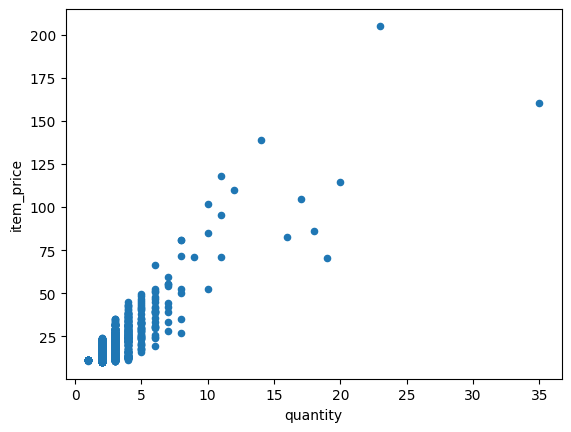

In [47]:
# make a scatter plot with item_price totals on the x-axis, total quantities on the y-axis.
# YOUR CODE BELOW
orderid_totals.plot(kind='scatter', x='quantity', y='item_price')



You can see this looks fairly linear as one would imagine: Total prices increase with total items purchased. But we can see it for ourselves using the plot.


## Part 3: Movie Data

Open the dataset and load it into a DataFrame named 'movies_df`. Then answer the following questions:
1. What's the range of movie gross in the United States?
2. What genre of movies are most likely gain large audiences (comedies? action films?) Use a boxplot to visualize the relationship.
3. Which M.P.A.A. ratings get the biggest audiences (G?, R?). Again, a boxplot can let you compare each genre's US Gross.

### 1: Load the data


In [48]:
# the URL below points to the .csv file
movie_URL = "https://raw.githubusercontent.com/bsmith-classroom/datasets/main/movie-data.csv"

# load the data
movies_df = pd.read_csv(movie_URL)  # REPLACE "" with the code to read a .csv file into a dataframe

movies_df.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time (min),Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083,146083,NaN,8000000.0,12-Jun-98,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876,10876,NaN,300000.0,7-Aug-98,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134,203134,NaN,250000.0,28-Aug-98,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615,373615,NaN,300000.0,11-Sep-98,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819,1087521,NaN,1000000.0,9-Oct-98,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


### 2. What's the range of movie gross in the United States?
We want to find the minimum and maximum grossing films in the U.S. Before we do that, we'd better check for missing values. Remember how to do that? Use `isna()` or take a look at the dataframe with `info()`

In [53]:
# check movies_df for missing values
movies_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3201 non-null   object 
 1   US Gross                3201 non-null   object 
 2   Worldwide Gross         3201 non-null   object 
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   object 
 6   MPAA Rating             2596 non-null   object 
 7   Running Time (min)      1209 non-null   float64
 8   Distributor             2969 non-null   object 
 9   Source                  2836 non-null   object 
 10  Major Genre             2926 non-null   object 
 11  Creative Type           2755 non-null   object 
 12  Director                1870 non-null   object 
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   

There are missing values in the DataFrame, no surprise. The good news for us is that the `US Gross` column has all of its values. It's a miracle!  

So this is easy...all you have to do is read off the minimum and maximum values using the `.describe()` function.

In [52]:
# call .describe() on movies_df to see the minimum and maximum values of 'US Gross'.
movies_df.describe()

,US DVD Sales,Production Budget,Running Time (min),Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
count,5.640000e+02,3.200000e+03,1209.000000,2321.000000,2988.000000,2988.000000
mean,3.490155e+07,3.106917e+07,110.193548,54.336924,6.283467,29908.644578
std,4.589512e+07,3.558591e+07,20.171014,28.076593,1.252290,44937.582335
min,6.184540e+05,2.180000e+02,46.000000,1.000000,1.400000,18.000000
25%,9.906211e+06,6.575000e+06,95.000000,30.000000,5.600000,4828.500000
50%,2.033156e+07,2.000000e+07,107.000000,55.000000,6.400000,15106.000000
75%,3.779422e+07,4.200000e+07,121.000000,80.000000,7.200000,35810.500000
max,3.525821e+08,3.000000e+08,222.000000,100.000000,9.200000,519541.000000


Hang on, where is `US Gross`? `.describe()` gives descriptive statistics for all **numeric** columns in a DataFrame. Let's check the type of the values in the `US Gross` column.

In [54]:
# .dtypes will tell us the column's data type
print("Data in US Gross are of type", movies_df['US Gross'].dtypes)

Data in US Gross are of type object


Ah. The column holds "objects," not numbers. We can convert the column using `.astype()`. Set the `US Gross` column equal to itself but make the value integers (`.astype(int)`).

In [61]:
# set the US Gross column to have integer types
movies_df['US Gross'] = movies_df['US Gross'].astype(int)

ValueError: invalid literal for int() with base 10: 'Unknown'

Wow, that was unexpected. Take a look at the last line of the error that reads:  

<span style='color: red;'>ValueError</span>: invalid literal for int() with base 10: 'Unknown'  

'Unknown'. This error is telling us Python tried to change values into integers. And then it hit a string with the value 'Unknown'. There were no missing values in this column. That is, there were no missing values labeled `NaN`. Do we have values in the column equal to `Unknown`? Write a piece of code below to check this.


In [64]:
# check to see if any values in the 'US Gross' column equal 'Unknown'.
# Hint: there are a lot of rows in this dataframe. You might want to use sum()
# or value_counts()...something to summarize the results
movies_df['US Gross'].value_counts()
# Additional hint: You can look for things that equal (==) 'Unknown'. Or we should
# only see numbers in this column. You could check to see what values are numbers using
# .isnumeric(). There are a few ways to find the missing/Unknown values.



,count
US Gross,
0,66
8000000,9
7000000,7
2000000,7
Unknown,7
...,...
130058047,1
7013191,1
7314027,1


You should have found 7 'Unknown' values in movies_df. We can set the movies_df equal to a version of itself where we eliminate the `Unknown` values in `US Gross` using a filter expression. Remember how to do this?

```
df = df[df[<some_column> <boolean expression here>]]
```

In [68]:
# filter US Gross to keep values that don't equal 'Unknown'
movies_df = movies_df[movies_df['US Gross'] != "Unknown"]
# checking to see that all the Unknown values are gone
assert (movies_df['US Gross'] == 'Unknown').sum() == 0, "'Unknown' found in movies_df"


Now that we got rid of those strings, we can try converting the column to integer values. Give it another shot.

In [69]:
# set the US Gross column to have integer types using .astype(int)
movies_df['US Gross'] = movies_df['US Gross'].astype(int)
# check to see that the column is int
movies_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 3194 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3194 non-null   object 
 1   US Gross                3194 non-null   int64  
 2   Worldwide Gross         3194 non-null   object 
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3193 non-null   float64
 5   Release Date            3194 non-null   object 
 6   MPAA Rating             2594 non-null   object 
 7   Running Time (min)      1209 non-null   float64
 8   Distributor             2968 non-null   object 
 9   Source                  2834 non-null   object 
 10  Major Genre             2925 non-null   object 
 11  Creative Type           2754 non-null   object 
 12  Director                1869 non-null   object 
 13  Rotten Tomatoes Rating  2316 non-null   float64
 14  IMDB Rating             2983 non-null   float

/tmp/ipykernel_1289/2455299168.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  movies_df['US Gross'] = movies_df['US Gross'].astype(int)


You should see the `Dtype` of `US Gross` is now `int64`. Now we can finally get the range of US grossing movies. Here's a great thing: You can call `min()` and `max()` on the column to get the minimum and maximum values.

In [71]:
max_US_gross = movies_df['US Gross'].max()  # Replace 0 with code that computes .max()
min_US_gross = movies_df['US Gross'].min()  # Replace 0 with code that computes .min()

print(f"Max gross = {max_US_gross}, min gross = {min_US_gross}")


Max gross = 760167650, min gross = 0


The minimum gross is zero dollars. That's not really useful. Why don't we get rid of the zero values and then recalculate the minimum.

In [74]:
# get a dataframe that only holds `US Gross` values > 0
movies_with_real_gross_df = movies_df[movies_df['US Gross'] > 0]   # REPLACE "" with a filter on movies_df to get values > 0

# Replace 0  below with code that computes .min() for movies with gross > 0
min_US_gross = movies_with_real_gross_df['US Gross'].min()

# compute the range, the difference between max and min gross values
US_gross_range = movies_with_real_gross_df['US Gross'].max() - movies_with_real_gross_df['US Gross'].min()

# print the values
print(f"Max gross = {max_US_gross}, min gross = {min_US_gross}")
print("US gross range is", US_gross_range)

# checking values
assert min_US_gross == 401, "The minimum gross should equal 401"
assert max_US_gross == 760167650, "The minimum gross should equal 760167650"
assert US_gross_range == 760167249, "The gross range should equal 760167249"



Max gross = 760167650, min gross = 401
US gross range is 760167249


### 3. Which M.P.A.A. ratings get the biggest audiences (G?, R?) Visualize this with a boxplot.

Let's start by looking at head of movies_df.

In [75]:
# look at the head of movies_df
movies_df.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time (min),Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083,146083,NaN,8000000.0,12-Jun-98,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876,10876,NaN,300000.0,7-Aug-98,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134,203134,NaN,250000.0,28-Aug-98,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615,373615,NaN,300000.0,11-Sep-98,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819,1087521,NaN,1000000.0,9-Oct-98,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


There's a lot here that we don't need. Let's make a new DataFrame called `mpaa_df`. We'll pull to columns into this from movies_df, 'US Gross' and 'MPAA Rating'. You'll want to provide these as a list when you index the movies_df frame.  

By the way, why are we pulling 'US Gross'? We don't have a column that gives the number of people who saw a movie. All we have is the gross revenues. So we'll use `US Gross` to mean "mo' $$, mo` eyes on the screen."

In [76]:
# create mpaa_df with the columns 'US Gross' and 'MPAA Rating'
mpaa_df = movies_df[['US Gross', 'MPAA Rating']]

# Once you make the frame, let's drop any missing values.
mpaa_df.dropna()
# check to see that there are no missing values remaining
display(mpaa_df.isna().sum())

# check that there are only two columns, US Gross and MPAA Rating
assert set(mpaa_df.columns) == {'US Gross', 'MPAA Rating'}

,0
US Gross,0
MPAA Rating,600


**Now** let's make the boxplot using ratings_gross. There are a lot of ways to make boxplots. For the kind of data we have here—each row has an instance of a categorical variable (MPAA Rating)-it's easist to use `seaborn`'s `boxplot. The command looks like this:

```
sns.boxplot(x=column_name, y=column_name, data=dataframe)
```

Call `sns.boxplot` below with the mpaa_df and columns. And add an additional argument to your function: `showfliers=False`. This will make the plot look cleaner by removing outlier dots that seaborn uses by default.

<Axes: xlabel='US Gross', ylabel='MPAA Rating'>

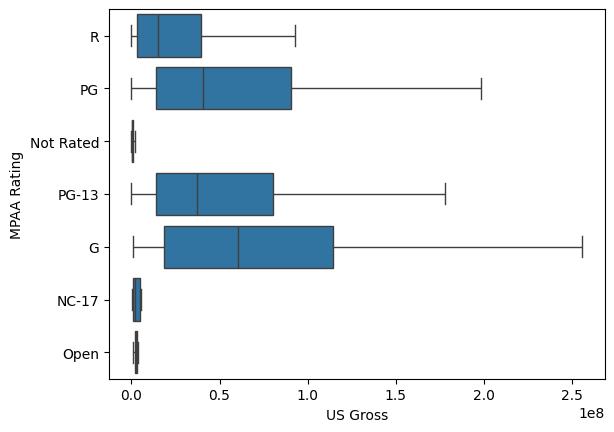

In [77]:
# call sns.boxplot below. set showfliers=False
sns.boxplot(x='US Gross', y='MPAA Rating', data=mpaa_df, showfliers=False)

It's not pretty, but you should see the mean lines in the boxes. Which one is highest? In other words, which movie rating earned the most US revenue? Set the variable `biggest_audience_rating` below to the rating with the top performer.


<Axes: xlabel='US Gross', ylabel='MPAA Rating'>

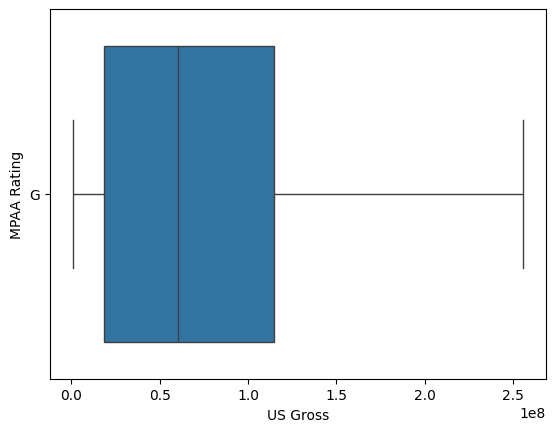

In [82]:
biggest_audience_rating = mpaa_df[mpaa_df['MPAA Rating'] == 'G']    # place the highest rating in between the quotes

sns.boxplot(x='US Gross', y='MPAA Rating', tit  data=biggest_audience_rating, showfliers=False)

Do a little clean up above. Add xlabel, ylabel, and a title.

### 3. Which M.P.A.A. ratings get the biggest audiences (G?, R?). Again, a boxplot can let you compare each genre's US Gross.
This question is almost identical to what we just did. The only difference is that we'll make a table called `genre_df.
1. Make genre_df have two columns, 'Major Genre' and 'US Gross'.
2. Get rid of missing values.
3. Use `sns.boxplot() to create a plot.
4. Use the plot to fill in the variable `biggest_audience_genre`.

<Axes: xlabel='US Gross', ylabel='Major Genre'>

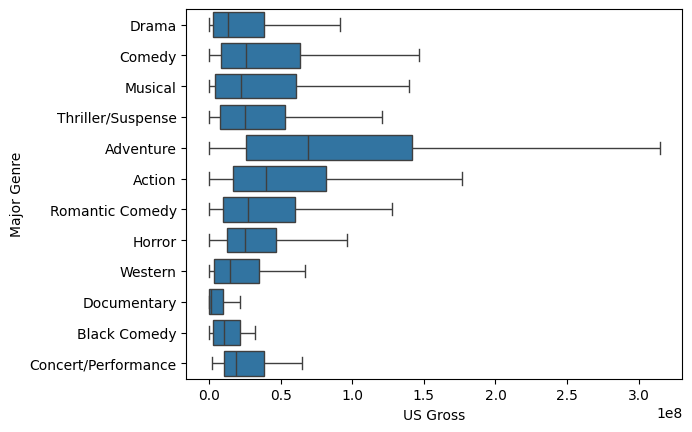

In [85]:
# YOUR CODE BELOW TO PLOT GENRE/US GROSS

biggest_audience_genre = movies_df[['US Gross', 'Major Genre']]    # place the highest genre in between the quotes

sns.boxplot(x='US Gross', y='Major Genre', data=biggest_audience_genre, showfliers=False)

## Done!
Three datasets explored, well done! Submit your completed notebook through Canvas and take a break from Python!